# Graph Models - Additional Features (MLX)

General tutorials for graph features for MLX can be found [here](mlx_model.ipynb).

The following demos **adding additional features** to the graph data. These features are added to the graph latent space before being fed into the MLP network. To utilize this, data will need to prepared into graph information and instantiating the model Class will require a different parameter. All other parameters will work similarly as the previous tutorial.

 ## Import Modules

Unlike the PyTorch version, the MLX code will utilize the Apple Silicon GPU by default. No explicit stating of GPU or CPU is needed unless specifically specified.

In [1]:
import pandas as pd
from tqdm import tqdm
import numpy as np
import random
import mlx.core as mx
from mlx_graphs.loaders import Dataloader
from mminer_graphs.mlx_models import MolToGraph, GCNNet, GINENet, EarlyStopping, summary
from mminer_graphs.plot.mlx_plot import PlotsMLX

Optional: Setting the seed to ensure reproducibility.

In [2]:
random.seed(451)
np.random.seed(451)
mx.random.seed(451)

## Dataset Prep
Again, this tutorial will use the dataset from [MoleculeNet](https://moleculenet.org) and uses their BACE dataset. This dataset includes quantitative (IC50) and qualitative (binary labels) binding results for inhibitors of human beta secretase (BACE-1). The only modification to the dataset was replacing their default split with a random split and including cross-validation columns with random splits.

Additional features from the dataset will be included as additional features during model training.

In [3]:
dataset = pd.read_csv("../dataset/bace.csv")
data = dataset.copy()
print(f"The shape of the dataset: {data.shape}")
data.head()

The shape of the dataset: (1513, 605)


,smiles,CID,Class,Model,pIC50,MW,AlogP,HBA,HBD,RB,...,CV0,CV1,CV2,CV3,CV4,CV5,CV6,CV7,CV8,CV9
0,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,BACE_1,1,train,9.154901,431.56979,4.4014,3,2,5,...,train,train,train,train,train,train,test,train,train,train
1,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,BACE_2,1,train,8.853872,657.81073,2.6412,5,4,16,...,train,train,train,train,train,train,train,train,train,test
2,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,BACE_3,1,train,8.698970,591.74091,2.5499,4,3,11,...,train,train,train,train,test,train,train,train,train,train
3,S1(=O)(=O)C[C@@H](Cc2cc(O[C@H](COCC)C(F)(F)F)c...,BACE_4,1,train,8.698970,591.67828,3.1680,4,3,12,...,train,train,train,train,test,train,train,train,train,train
4,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,BACE_5,1,train,8.698970,629.71283,3.5086,3,3,11,...,train,train,train,train,train,train,train,train,test,train


The additional features will be extracted. For this case, 10 features will be extracted.

In [4]:
# extra features
extra_cols = ["MW", "AlogP", "HBA", "HBD", "RB", "HeavyAtomCount", "ChiralCenterCount",
              "ChiralCenterCountAllPossible", "RingCount", "PSA"]
extra_data = dataset[extra_cols]
extra_list = extra_data.values.tolist()

## Convert to Graph Data

The dataset will need to be converted to graphs. However, this time additional features will be added to the graphs. For MolMiner-Graphs, additional features must be labeled under **add_feats**. An example of how to prepare this can be seen below:

In [5]:
train = data[data.iloc[:, -1] == 'train']
test = data[data.iloc[:, -1] == 'test']

train_list = [MolToGraph(smi=smi, label=y, add_feats=extra).graph_data for smi, y, extra in tqdm(zip(train.smiles, train.Class, extra_list), desc="Converting Train Graphs")]
test_list = [MolToGraph(smi=smi, label=y, add_feats=extra).graph_data for smi, y, extra in tqdm(zip(test.smiles, test.Class, extra_list), desc="Converting Test Graphs")]

Converting Train Graphs: 1376it [00:02, 605.07it/s]
Converting Test Graphs: 137it [00:00, 600.45it/s]


This will generate a list containing mlx-graph Data objects with four MLX arrays. The shapes of the arrays are:
* **x** = [num_nodes, num_features]
* **edge_index** = [2, num_edge_features]
* **edge_attr** = [num_edges, num_edge_features]
* **y** = [class_label]

In [6]:
train_list[:1]

[GraphData(
 	edge_index(shape=(2, 70), int32)
 	node_features(shape=(32, 142), float32)
 	edge_features(shape=(70, 16), float32)
 	y(shape=(1,), float32)
 	add_feats(shape=(10,), float32))]

*Optional*

The graph model classes requires the data to be in a list or as a PyG DataLoader(). If a list is given, then the list will be converted into the PyTorch class DataLoader internally (so this section can technically be deleted). In this part of the tutorial, the list will be converted into a Dataloader class.

In [7]:
# load data
train_loader = Dataloader(train_list, batch_size=1024, shuffle=True)  # shuffle to avoid overfitting to sample order
test_loader = Dataloader(test_list, batch_size=1024)

print(f"Training Data: {len(train_loader.dataset)}")
print(f"Test Data: {len(test_loader.dataset)}")

Training Data: 1376
Test Data: 137


The graph information set as a DataLoader can be visualized using .dataset. This will generate a list of the graph data. Only the first 5 are printed to save space.


In [8]:
train_loader.dataset[:5]

[GraphData(
 	edge_index(shape=(2, 70), int32)
 	node_features(shape=(32, 142), float32)
 	edge_features(shape=(70, 16), float32)
 	y(shape=(1,), float32)
 	add_feats(shape=(10,), float32)),
 GraphData(
 	edge_index(shape=(2, 92), int32)
 	node_features(shape=(42, 142), float32)
 	edge_features(shape=(92, 16), float32)
 	y(shape=(1,), float32)
 	add_feats(shape=(10,), float32)),
 GraphData(
 	edge_index(shape=(2, 84), int32)
 	node_features(shape=(40, 142), float32)
 	edge_features(shape=(84, 16), float32)
 	y(shape=(1,), float32)
 	add_feats(shape=(10,), float32)),
 GraphData(
 	edge_index(shape=(2, 96), int32)
 	node_features(shape=(44, 142), float32)
 	edge_features(shape=(96, 16), float32)
 	y(shape=(1,), float32)
 	add_feats(shape=(10,), float32)),
 GraphData(
 	edge_index(shape=(2, 82), int32)
 	node_features(shape=(39, 142), float32)
 	edge_features(shape=(82, 16), float32)
 	y(shape=(1,), float32)
 	add_feats(shape=(10,), float32))]

## Training the Model

The training of the model with additional features requires using an additional parameter, **add_feats**. This parameter is an int and must match the number of features in the add_feats MLX array.

**NOTE:** The code has not been tested for multi-label or regression models.

In [9]:
model = GCNNet(node_dim=142, hidden_dim=128, graph_layers=3, mlp_layers=2, reduce_graph=False, num_classes=2, add_feats=10)
model

GCNNet(
  (gcn_conv.0): GCNConv(
    (linear): Linear(input_dims=142, output_dims=128, bias=True)
  )
  (gcn_conv.1): GCNConv(
    (linear): Linear(input_dims=128, output_dims=128, bias=True)
  )
  (gcn_conv.2): GCNConv(
    (linear): Linear(input_dims=128, output_dims=128, bias=True)
  )
  (normalization.0): BatchNorm(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (normalization.1): BatchNorm(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (normalization.2): BatchNorm(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (mlp.0): Sequential(
    (layers.0): Linear(input_dims=138, output_dims=69, bias=True)
    (layers.1): BatchNorm(69, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (layers.2): ReLU()
    (layers.3): Dropout(p=0.0)
  )
  (final_mlp): Linear(input_dims=69, output_dims=2, bias=True)
)

The GCNNet class above was set to the variable **model**. This can be printed to check on the created model. This will print out the model, its graph, and its MLP layers.

A summary in tabular format can also be printed by using the **summary()** method. This requires the instantiated model and the dataset used for training/testing.

In [10]:
print(summary(model))

GCNNet                                             Shape                              Params
└─(gcn_conv)                                       --                                 51,328
    ├─(0)                                          --                                 18,304
    │   └─(linear)                                 --                                 18,304
    │       ├─(weight)                             (128, 142)                         18,176
    │       └─(bias)                               (128,)                                128
    ├─(1)                                          --                                 16,512
    │   └─(linear)                                 --                                 16,512
    │       ├─(weight)                             (128, 128)                         16,384
    │       └─(bias)                               (128,)                                128
    └─(2)                                          --                 

**EarlyStopping** can also be set. Here it will be called to monitor the validation/test data.

In this tutorial, the **EarlyStopping** class is instantiated, but the patience is set at 100.

In [11]:
estop = EarlyStopping(monitor='val_loss', patience=75, mode='min')

The model can be fit in a similar fashion to the sklearn api by calling the **.fit()** instance method. There are several mandatory parameters needed to ensure that the model is fitted:
- The training dataset
- The test dataset

Additional parameters include setting the epochs number, the optimizer, and using early stopping (estop). A special parameter, **device** will determine where the MLX arrays are to be trained. By default, this is set to "auto" and will utilize the Apple Silicon gpu.

In [12]:
model.fit(train_loader, test_loader, epochs=100, batch_size=1024, optimizer="adam", estop=estop, criterion="cross_entropy", lr=0.001)

Model running on Apple M2 Pro


Epoch: 100%|██████████| 100/100 [00:36<00:00,  2.73it/s]

Best Training Loss: 0.085
Best Test Loss: 0.443
Best Training Accuracy: 0.976
Best Test Accuracy: 0.796


## Plots

The mol-miner-graphs comes with basic plot functions. This section will demo their usage.

### Curves
The **curves()** method will generate the loss curve and accuracy curves for the model. It will use the results from the Test data. The figure here is drawn with default settings, however the **curves()** method contains additional parameters, such as line colors, figsize, or other metrics to plot (Precision).

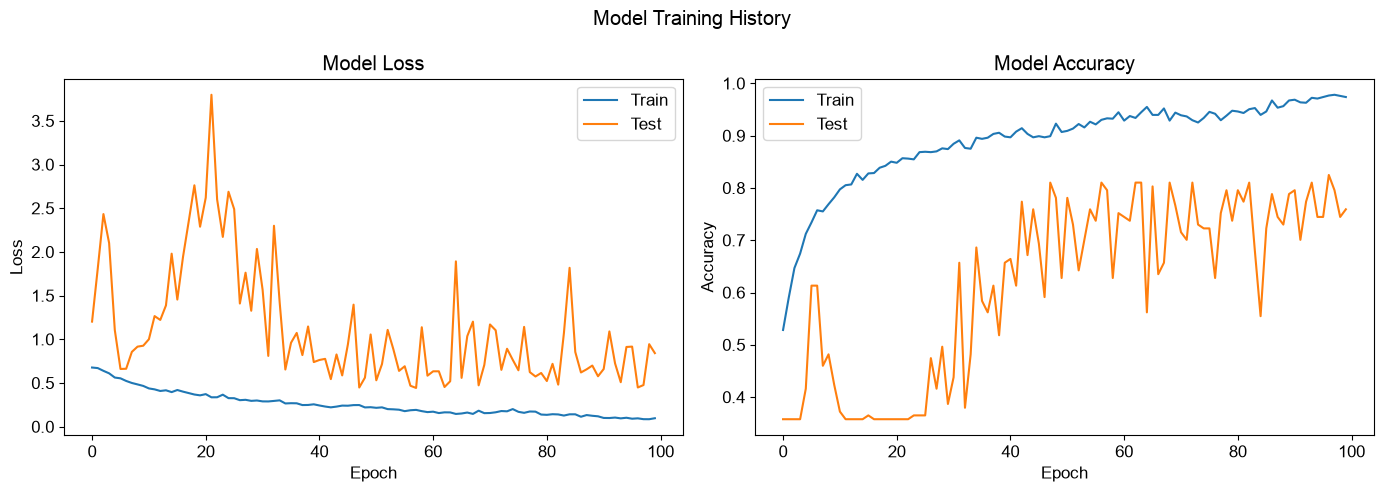

In [13]:
plot = PlotsMLX(model, data_loader=test_loader, add_feats=10)
plot.curves()

### Confusion Matrix

A confusion matrix can be drawn using the **confusion_matrix()** method. The class names will default to 0 and 1. Here, they are renamed as "Inactive" and "Active" using the **class_names** parameter. The device is an important parameter and should be modified to be the same input as what was used in the **.fit()** instance variable. For example, if the model was fitted using 'cpu', then the confusion matrix device should be set to 'cpu'. Additional parameters are available to modify the title, figsize, and cmap.

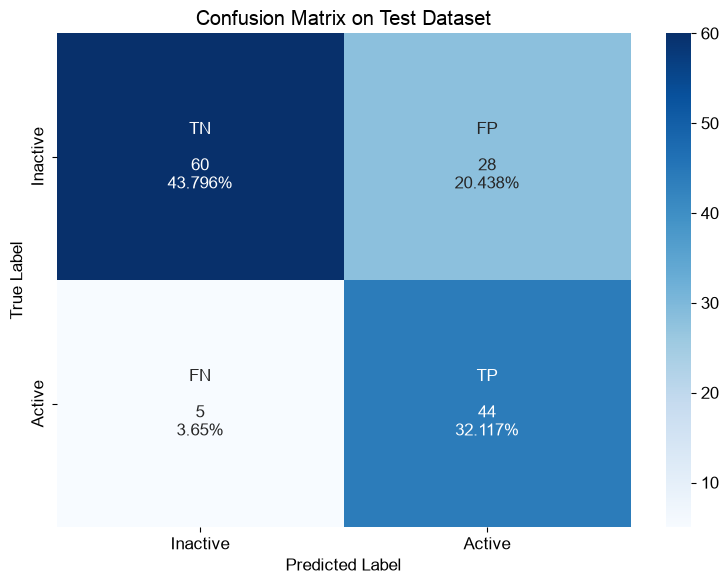

In [14]:
plot.confusion_matrix(class_names=['Inactive', 'Active'])

plot.confusion_matrix(class_names=['Inactive', 'Active'])

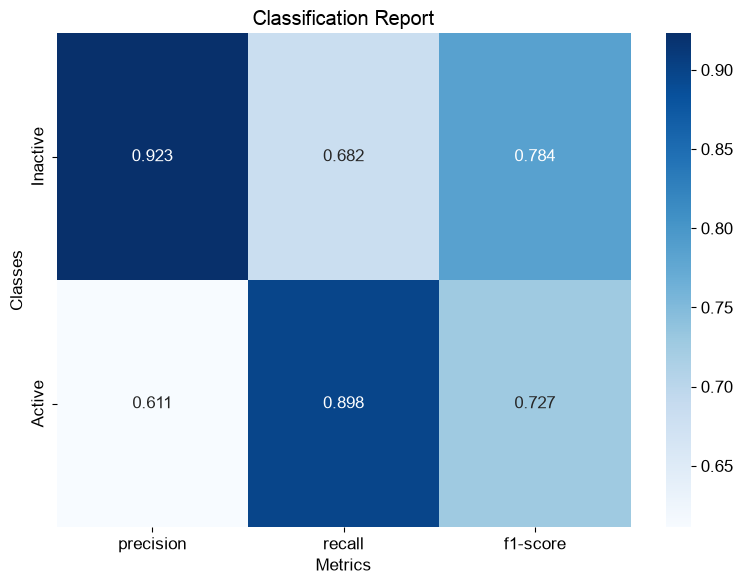

In [15]:
plot.classification_report(class_names=['Inactive', 'Active'])

An **[roc_curve()](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html)** can be drawn and displays the classifier output quality.

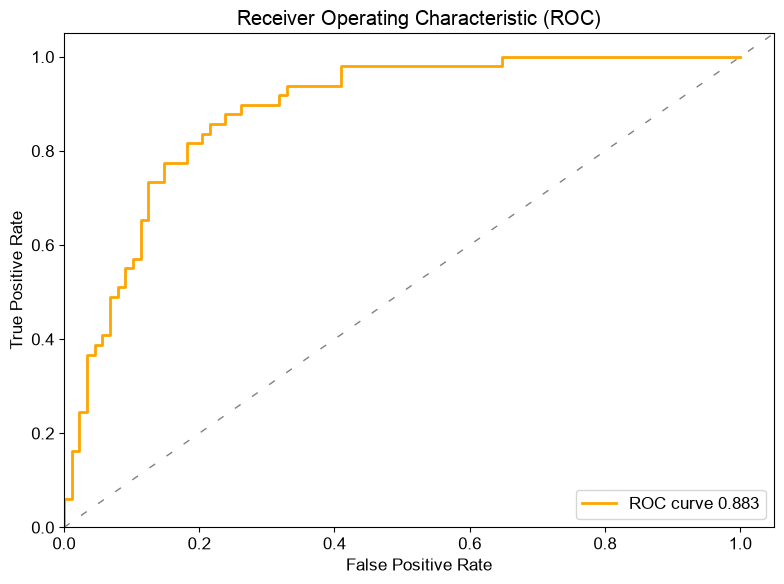

In [16]:
plot.roc_curve(model=model)

The **[pr_curve()](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html)** can be drawn to show the tradeoff between precision and recall for different thresholds.

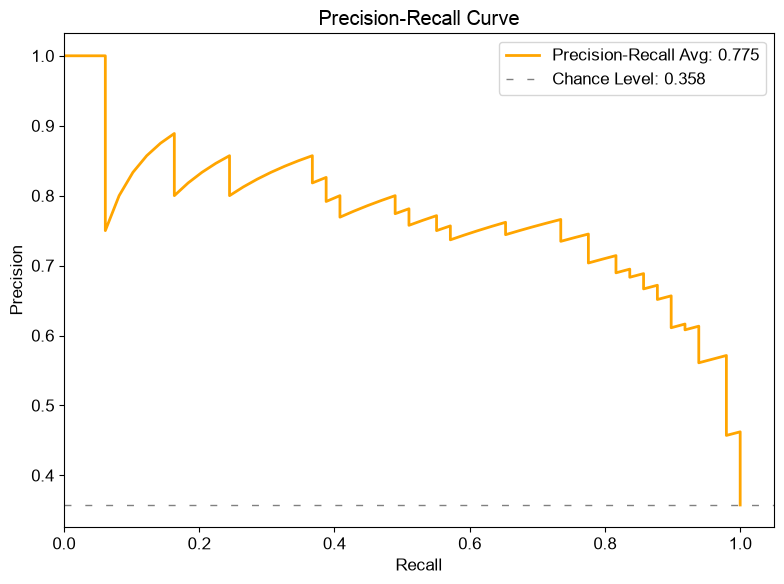

In [17]:
plot.pr_curve(model=model, chance_level=True)

## Making Predictions

Additionally, the mol-miner-graphs package contains a **.predict()** for easier usability. This will output a list of results on a tensor. By default, the **.predict()** method  it will output results as a list for easier use with pd.DataFrames. In this example, the results are given as a MLX array.

If the model was trained with additional features, then the number of additional features are taken from the initial class parameter.

In [18]:
pred = model.predict(test_loader, batch_size=1024, binary=True, return_type="list")
df = pd.DataFrame(pred)
df

,0
0,1
1,1
2,1
3,1
4,1
...,...
132,0
133,0
134,0
135,0


# Regression

Regression models are built similarly to Classification models demoed above. The main parameter changes are with the criterion and the num_classes.

## Dataset Prep
The dataset for this example will use the same as above, with the dataset taken form [MoleculeNet](https://moleculenet.org) and uses their BACE dataset. Instead of qualitative binding (binary labels) , the demo will utilize the quantitative (pIC50) labels for inhibitors of human beta secretase (BACE-1).

The dataset will be prepared as follows:

In [19]:
dataset = data.copy()
dataset.head()

,smiles,CID,Class,Model,pIC50,MW,AlogP,HBA,HBD,RB,...,CV0,CV1,CV2,CV3,CV4,CV5,CV6,CV7,CV8,CV9
0,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,BACE_1,1,train,9.154901,431.56979,4.4014,3,2,5,...,train,train,train,train,train,train,test,train,train,train
1,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,BACE_2,1,train,8.853872,657.81073,2.6412,5,4,16,...,train,train,train,train,train,train,train,train,train,test
2,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,BACE_3,1,train,8.698970,591.74091,2.5499,4,3,11,...,train,train,train,train,test,train,train,train,train,train
3,S1(=O)(=O)C[C@@H](Cc2cc(O[C@H](COCC)C(F)(F)F)c...,BACE_4,1,train,8.698970,591.67828,3.1680,4,3,12,...,train,train,train,train,test,train,train,train,train,train
4,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,BACE_5,1,train,8.698970,629.71283,3.5086,3,3,11,...,train,train,train,train,train,train,train,train,test,train


In [20]:
# extra features
extra_cols = ["PSA", "MW", "AlogP", "HBA", "HBD", "RB", "HeavyAtomCount", "ChiralCenterCount",
              "ChiralCenterCountAllPossible", "RingCount"]
extra_data = dataset[extra_cols]
extra_list = extra_data.values.tolist()

# create array of graphs for train/test
train_list = [MolToGraph(smi=smi, label=y, add_feats=extra).graph_data for smi, y, extra in tqdm(zip(train.smiles, train.pIC50, extra_list), desc="Converting Train Graphs")]
test_list = [MolToGraph(smi=smi, label=y, add_feats=extra).graph_data for smi, y, extra in tqdm(zip(test.smiles, test.pIC50, extra_list), desc="Converting Test Graphs")]

Converting Train Graphs: 1376it [00:02, 573.40it/s]
Converting Test Graphs: 137it [00:00, 588.28it/s]


In [21]:
train_list[:1]

[GraphData(
 	edge_index(shape=(2, 70), int32)
 	node_features(shape=(32, 142), float32)
 	edge_features(shape=(70, 16), float32)
 	y(shape=(1,), float32)
 	add_feats(shape=(10,), float32))]

## Training the Model
Training the model will work similarly to the Classification model above. For this example, a GINE model will be created instead. Note that for Regression models, the num_classes is set to 1. The parameter **add_feats** will also need to be given to ensure additonal features are used.

In [22]:
model = GINENet(node_dim=142, edge_feat_dim=16, hidden_dim=128, graph_layers=3, mlp_layers=2, reduce_graph=False, graph_dropout= 0, mlp_dropout=0, num_classes=1, add_feats=10)

In [23]:
print(summary(model))

GINENet                                            Shape                              Params
└─(gine_conv)                                      --                                109,166
    ├─(0)                                          --                                 37,742
    │   ├─(mlp)                                    --                                 35,328
    │   │   └─(layers)                             --                                 35,328
    │   │       ├─(0)                              --                                 18,304
    │   │       │   ├─(weight)                     (128, 142)                         18,176
    │   │       │   └─(bias)                       (128,)                                128
    │   │       ├─(1)                              --                                    512
    │   │       │   ├─(weight)                     (128,)                                128
    │   │       │   ├─(bias)                       (128,)             

### Fitting the Model

For regression models, the criterion will need to be changed. All other parameters should be similar to what was used for Classification models.

In [24]:
model.fit(train_list, test_list, epochs=100, batch_size=1024, optimizer="adam", estop=estop, criterion="mse", lr=0.001)

Model running on Apple M2 Pro


Epoch: 100%|██████████| 100/100 [00:20<00:00,  4.77it/s]


Best Training Loss: 0.029
Best Test Loss: 0.328
Best Training MAE: 0.171
Best Test MAE: 0.59


## Plot

### Curves
The **curves()** method will generate the loss curve and the associated Regression metric. What is plotted can be given as a list.

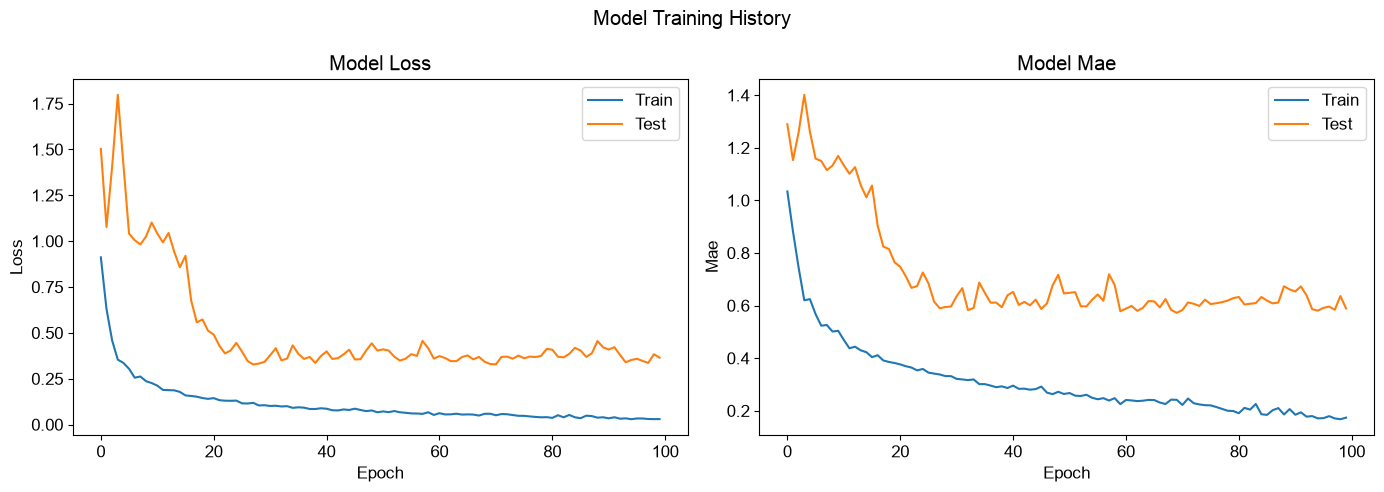

In [25]:
plot = PlotsMLX(model, data_loader=test_list, add_feats=10)
plot.curves(metrics=['loss', 'mae'])

For Regression models, a regression plot can be drawn.

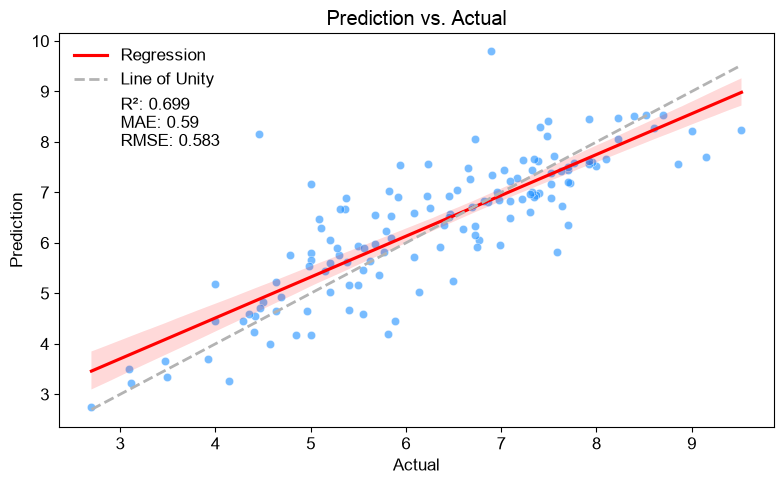

In [26]:
plot.regression()

## Saving and Loading a Model
After fitting a model, they can be saved and loaded using the **.save()** or **.load()** instance variables. For MLX models, the saved model must have the *.npz* extension.

In [27]:
model.save("test.npz")

To load a molecule, a model must be initialized using the same param as was used for saved model. For this example, teh same GCNNet used above was pasted to reset the model variable.

In [28]:
model = GINENet(node_dim=142, edge_feat_dim=16, hidden_dim=128, graph_layers=3, mlp_layers=2, reduce_graph=False, graph_dropout= 0, mlp_dropout=0, num_classes=1, add_feats=10)
print(f"Is the model fitted? {model.is_fitted}")

Is the model fitted? False


The saved model is then loaded using the **.load()** instance variable. Note that the device for laoding the model also uses CPU. A summary of the model can be seen below.

In [29]:
model.load("test.npz", criterion="mse")
print(f"Is the model fitted? {model.is_fitted}")
print(f"\n\n{summary(model)}")

Model loaded!
Is the model fitted? True


GINENet                                            Shape                              Params
└─(gine_conv)                                      --                                109,166
    ├─(0)                                          --                                 37,742
    │   ├─(mlp)                                    --                                 35,328
    │   │   └─(layers)                             --                                 35,328
    │   │       ├─(0)                              --                                 18,304
    │   │       │   ├─(weight)                     (128, 142)                         18,176
    │   │       │   └─(bias)                       (128,)                                128
    │   │       ├─(1)                              --                                    512
    │   │       │   ├─(weight)                     (128,)                                128
    │   │       │   ├─(bias)